In [1]:
print("all ok")

all ok


In [2]:
def hello_node(input:str):
    return {"message": f"Hello, {input}!"}

In [3]:
hello_node("Pratibha")

{'message': 'Hello, Pratibha!'}

In [4]:
hello_node("prakash")

{'message': 'Hello, prakash!'}

In [5]:
hello_node("langgraph")

{'message': 'Hello, langgraph!'}

In [6]:
from typing_extensions import TypedDict

In [7]:
class State(TypedDict):
    message: str

In [8]:
class State:
    message: str

In [9]:
State()

In [10]:
state: State = {"message": "hello python"}

In [11]:
State

__main__.State

In [12]:
def hello_node(state: State):
    return {"message": f"Hello, {state['message']}!"}

In [1]:
from langgraph.graph import StateGraph, START, END

In [3]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    messages: list

In [4]:
builder = StateGraph(State)

In [6]:
def hello_node(state):
    print("Hello from the first node!")
    return state

In [7]:
builder.add_edge(START,"first_hello_node")

In [8]:
builder.add_edge("first_hello_node", END)

In [9]:
graph = builder.compile()

ValueError: Found edge starting at unknown node 'first_hello_node'

In [10]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [11]:
class State(TypedDict):
    message: str

In [12]:
def hello_node(state: State):
    print("Hello from the first node!")
    return {
        "message": "Hello World"
    }

In [13]:
builder = StateGraph(State)

In [14]:
builder.add_node("first_hello_node", hello_node)

In [15]:
builder.add_edge(START, "first_hello_node")
builder.add_edge("first_hello_node", END)

In [16]:
graph = builder.compile()

In [17]:
result = graph.invoke({"message": ""})
print(result)

Hello from the first node!
{'message': 'Hello World'}


In [18]:
graph = builder.compile()

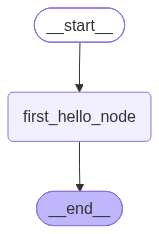

In [19]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [20]:
graph.invoke({"message": "from INDIA"})

Hello from the first node!


{'message': 'Hello World'}

In [21]:
result = graph.invoke({"message": "from INDIA"})

Hello from the first node!


In [22]:
result["message"]

'Hello World'

In [23]:
class Sunny(TypedDict):
    text: str

In [24]:
state: Sunny = {"text": "hello"}

In [25]:
def function1(state: Sunny):
    print(f"state from first function : {state}")
    return {
        "text": state["text"] + " from first function"
    }

In [26]:
def function2(state: Sunny):
    print(f"state from second function : {state}")
    return {
        "text": state["text"] + " savita from second function"
    }

In [27]:
workflow = StateGraph(Sunny)

In [28]:
workflow.add_node("fun1", function1)
workflow.add_node("fun2", function2)

In [29]:
workflow.add_edge(START, "fun1")
workflow.add_edge("fun1", "fun2")
workflow.add_edge("fun2", END)

In [30]:
app = workflow.compile()

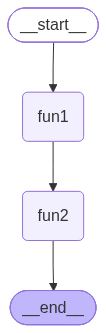

In [31]:
from IPython.display import Image, display

display(
    Image(
        app.get_graph().draw_mermaid_png()
    )
)

In [32]:
result = app.invoke({"text": "hi this is sunny"})

state from first function : {'text': 'hi this is sunny'}
state from second function : {'text': 'hi this is sunny from first function'}


In [33]:
result

{'text': 'hi this is sunny from first function savita from second function'}

In [34]:
result["text"]

'hi this is sunny from first function savita from second function'

In [35]:
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage

ModuleNotFoundError: No module named 'langchain_groq'

In [36]:
from dotenv import load_dotenv
import os

load_dotenv()

True

In [38]:
if not os.getenv("GROQ_API_KEY"):
    raise ValueError(
        "GROQ_API_KEY not found. Please add it to your .env file."
    )


In [6]:
%pip install -U langchain-groq

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
from langchain_groq import ChatGroq

In [8]:
MODEL_NAME = "openai/gpt-oss-20b"

llm = ChatGroq(
    model=MODEL_NAME,
    temperature=0.6,
    reasoning_format="hidden"
)

print(llm)

metadata={'lc_versions': {'langchain-core': '1.6.6'}} profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True} client=<groq.resources.chat.completions.Completions object at 0x000002119C4A49B0> async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002119C5BA1E0> model_name='openai/gpt-oss-20b' temperature=0.6 reasoning_format='hidden' model_kwargs={} groq_api_key=SecretStr('**********')


In [10]:
response = llm.invoke("What is LangGraph? Explain in one sentence.")
print(response.content)

AuthenticationError: Error code: 401 - {'error': {'message': 'Invalid API Key', 'type': 'invalid_request_error', 'code': 'invalid_api_key'}}

In [41]:
from langgraph.graph import MessagesState

In [13]:
def call_model(state: MessagesState):

    print("\n=========================")
    print("MYBOT NODE")
    print("=========================")

    # Get complete conversation history
    messages = state["messages"]

    print(
        "Current Messages:",
        messages
    )

    # Send complete message history to LLM
    response = llm.invoke(messages)

    print("\nModel Response:",response.content)

    # MessagesState internally uses add_messages reducer.
    # Therefore the new AIMessage will be added
    # to the existing list of messages.
    return {
        "messages": [response]
    }

NameError: name 'MessagesState' is not defined

In [2]:
result = app.invoke({"text": "hi this is sunny"})

NameError: name 'app' is not defined